# 12 · One Layout Plan, Two Views (ENC and KEY)

**NHyDB 0.28.2 notebook series · v1**

NHyDB keeps the **schema** – realms, shapes, layouts, MATH formulas, indexes – outside the data file, in an encrypted **layout plan** with its own **key file**. This notebook shows the plan twice: as the encrypted file on disk and as the authorized view of an opened database. Then it attacks the files in eight different ways – and the engine refuses every time.

> **Who is this for?** This notebook starts with a short introduction and continues with runnable examples. **New to NHyDB?** Read from top to bottom – every idea is introduced before it is used. **Already know the basics?** Skip the sections marked 📘 *Background* and jump to the experiments marked ▶. All cells run from top to bottom; optional deep dives are marked ⏩ *Advanced*.

**What you will learn**

* which three files belong together and how they are bound to each other
* what the encrypted plan file really contains – and what it does not reveal
* the *authorized view*: the full schema, read through the API of an opened database
* how the plan generation follows every schema change
* *fail closed*: missing or manipulated files are detected and opening is refused
* the honest limits: the data file itself is **not** encrypted

**Recommended before:** [02](02_from_address_to_data_v1.ipynb) and [11 · What Actually Lives on Disk?](11_what_lives_on_disk_v1.ipynb).

### Setup

The next cell checks the environment and defines a few small plotting helpers used in
this notebook. It is collapsed because it is not about NHyDB itself – feel free to open
it. Every database in this notebook lives in a temporary folder that is removed at
the end.

In [1]:
import math
import os
import shutil
import sys
import tempfile

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

import nhydb

# --- environment check ---------------------------------------------------------
EXPECTED = "0.28.2"
print(f"Python {sys.version.split()[0]} · nhydb {nhydb.ENGINE_VERSION} · "
      f"file format {nhydb.FILE_FORMAT_VERSION} · matplotlib {matplotlib.__version__}")
if nhydb.ENGINE_VERSION != EXPECTED:
    print(f"⚠ This notebook was written for NHyDB {EXPECTED}; results may differ.")

# --- a private temporary folder for all databases of this notebook --------------
WORKDIR = tempfile.mkdtemp(prefix="nhydb_notebook_")


def db_path(name):
    """Path of a new database file inside the temporary folder."""
    return os.path.join(WORKDIR, name)


def cleanup():
    shutil.rmtree(WORKDIR, ignore_errors=True)


def file_sizes(path):
    """Sizes of the files that belong to a database (bytes)."""
    folder, base = os.path.split(path)
    return {f: os.path.getsize(os.path.join(folder, f))
            for f in sorted(os.listdir(folder)) if f.startswith(base)}


# --- one visual language for the whole series -----------------------------------
# Layer A (mathematical address space) = blue tones, layer B (logical data model) =
# green, layer C (storage engine) = slate grey. Lanes and boundary points belong to A.
COLORS = {
    "A": "#1d4ed8", "A_light": "#dbeafe",
    "B": "#15803d", "B_light": "#dcfce7",
    "C": "#475569", "C_light": "#e2e8f0",
    "NL": "#2563eb", "NR": "#7c3aed",
    "GZ": "#dc2626", "N0": "#9ca3af",
    "attention": "#ea580c", "ok": "#16a34a", "bad": "#dc2626",
}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})

import json
import re
import pandas as pd


def short(e):
    # exception text without temporary folder paths
    return type(e).__name__ + ": " + re.sub(r"(/[^\s/]+)+/", "", str(e))


def copy_db(src, folder, name=None):
    # copy the three files of a closed database into another folder
    os.makedirs(folder, exist_ok=True)
    dst = os.path.join(folder, name or os.path.basename(src))
    for suffix in ("", ".layout.enc", ".layout.key"):
        shutil.copy2(src + suffix, dst + suffix)
    return dst

Python 3.14.5 · nhydb 0.28.2 · file format 0.28.2 · matplotlib 3.11.2


## 📘 Background: data here, schema there

| File | Content | Protection |
|---|---|---|
| `X.nhydb` | the data: blocks with values, plus the identity cells R0,u1 | **not encrypted** |
| `X.nhydb.layout.enc` | the layout plan: realms, shapes, layouts, MATH formulas, indexes | **AES-256-GCM** encrypted, **HMAC-SHA256** authenticated |
| `X.nhydb.layout.key` | 32 random bytes – the key to the plan | file permissions `0600`; keep a copy in a safe place |

Without the plan the engine does not know what the bytes in the data file *mean*: which layout
owns which cells, which field is which, which formula a MATH layout uses. So the engine opens a
database **only** if all three files match each other exactly – otherwise it refuses
(*fail closed*).

## 1 · A database with something worth protecting

▶ **Run it:** a CLASSIC layout with two sensor readings, a MATH layout (notebook 05) with one
calibration value, and later an index.

In [2]:
LIVE = db_path("plant.nhydb")

with nhydb.create(LIVE) as db:
    db.create_realm(1, "sensors")
    db.create_shape(1, 1, "reading", [{"v": 1, "name": "sensor", "type": "utf8"},
                                      {"v": 2, "name": "temp_c", "type": "f64"}])
    db.create_classic_layout(1, 1, "readings", shape_id=1)
    db.put_dense_batch(1, 1, [["boiler", 71.5], ["pump", 40.25]], shape_id=1)
    db.create_math_map_layout("grid", ("x", "y"), u="x + 1", V="y", side="NR",
                              payload_type="utf8", layout_id=2)
    db.put_math(2, (1, 2), "calibration 2026")


def read_known_values(path, **options):
    # the values we expect to read back whenever the database opens
    with nhydb.open(path, **options) as db:
        return db.get_value(1, 1, 1), db.get_value(1, 2, 2), db.get_math(2, (1, 2))


EXPECTED = read_known_values(LIVE)
print("known values:", EXPECTED)
print("files:", file_sizes(LIVE))

known values: ('boiler', 40.25, 'calibration 2026')
files: {'plant.nhydb': 9256, 'plant.nhydb.layout.enc': 2734, 'plant.nhydb.layout.key': 158, 'plant.nhydb.lock': 0}


## 2 · How the three files are bound together

**Question:** What exactly makes the files "belong together"?

* The data file stores its identity in the system cells **R0,u1** (notebook 11): a database id,
  its own file name, the names of plan and key file, the **plan generation** and the **schema
  digest** of the active schema (an HMAC-SHA256 with a key derived from the layout key).
* The **key file** names the database id and file name it belongs to.
* The **plan file** names the database id, holds the encrypted schema of the current (and the
  previous) generation, and a MAC over everything.

In [3]:
with nhydb.open(LIVE) as db:
    meta = db.get_system_metadata()["cells"]
plan = json.load(open(LIVE + ".layout.enc"))
key_fields = sorted(json.load(open(LIVE + ".layout.key")))          # only the field NAMES

binding = pd.DataFrame([
    {"link": "database id", "data file (R0,u1)": meta["1"], "plan file": plan["db_id"], "key file": "db_id (same)"},
    {"link": "file name", "data file (R0,u1)": meta["2"], "plan file": "–", "key file": "db_name (same)"},
    {"link": "generation", "data file (R0,u1)": meta["5"], "plan file": [e["generation"] for e in plan["entries"]], "key file": "–"},
    {"link": "schema digest", "data file (R0,u1)": meta["6"][:16] + "…", "plan file": [e["sha256"][:16] + "…" for e in plan["entries"]], "key file": "–"},
    {"link": "scheme", "data file (R0,u1)": meta["8"], "plan file": "nonce + ciphertext + mac", "key file": "32-byte key (hidden)"},
]).set_index("link")
assert plan["db_id"] == meta["1"] and meta["5"] in [e["generation"] for e in plan["entries"]]
print("key file fields:", key_fields, "– the key value itself is never shown in this notebook")
binding

key file fields: ['contract', 'db_id', 'db_name', 'key_b64'] – the key value itself is never shown in this notebook


,"data file (R0,u1)",plan file,key file
link,,,
database id,07a6473e-f507-41db-8952-181c7be090c4,07a6473e-f507-41db-8952-181c7be090c4,db_id (same)
file name,plant.nhydb,–,db_name (same)
generation,1,"[0, 1]",–
schema digest,719aedf9b9865952…,"[de25d4b5415c8a98…, 719aedf9b9865952…]",–
scheme,AES-256-GCM + HMAC-SHA256,nonce + ciphertext + mac,32-byte key (hidden)


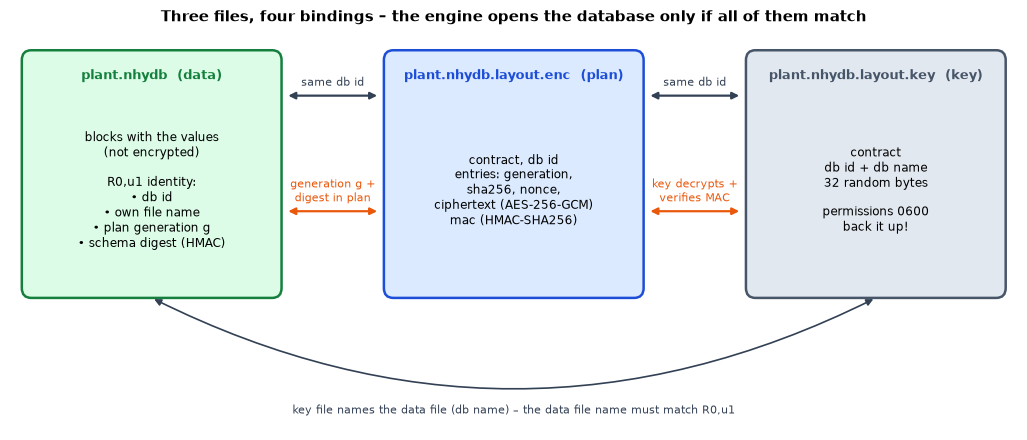

In [4]:
fig, ax = plt.subplots(figsize=(13, 5.2))
boxes = {
    "data": (0.0, 1.2, "B", "plant.nhydb  (data)",
             "blocks with the values\n(not encrypted)\n\nR0,u1 identity:\n• db id\n• own file name\n"
             "• plan generation g\n• schema digest (HMAC)"),
    "plan": (4.6, 1.2, "A", "plant.nhydb.layout.enc  (plan)",
             "contract, db id\nentries: generation,\nsha256, nonce,\nciphertext (AES-256-GCM)\n"
             "mac (HMAC-SHA256)"),
    "key": (9.2, 1.2, "C", "plant.nhydb.layout.key  (key)",
            "contract\ndb id + db name\n32 random bytes\n\npermissions 0600\nback it up!"),
}
for name, (x, y, layer, head, text) in boxes.items():
    ax.add_patch(FancyBboxPatch((x, y), 3.2, 2.9, boxstyle="round,pad=0.05,rounding_size=0.12",
                                facecolor=COLORS[layer + "_light"], edgecolor=COLORS[layer], lw=1.8))
    ax.text(x + 1.6, y + 2.6, head, ha="center", fontweight="bold", color=COLORS[layer], fontsize=9)
    ax.text(x + 1.6, y + 1.25, text, ha="center", va="center", fontsize=8.5)


def link(x1, x2, y, text, color):
    ax.annotate("", xy=(x2, y), xytext=(x1, y), arrowprops=dict(arrowstyle="<|-|>", color=color, lw=1.6))
    ax.text((x1 + x2) / 2, y + 0.12, text, ha="center", fontsize=8, color=color)


link(3.3, 4.5, 3.6, "same db id", "#334155")
link(3.3, 4.5, 2.2, "generation g +\ndigest in plan", COLORS["attention"])
link(7.9, 9.1, 3.6, "same db id", "#334155")
link(7.9, 9.1, 2.2, "key decrypts +\nverifies MAC", COLORS["attention"])
ax.annotate("", xy=(10.8, 1.15), xytext=(1.6, 1.15),
            arrowprops=dict(arrowstyle="<|-|>", color="#334155", lw=1.2, connectionstyle="arc3,rad=0.25"))
ax.text(6.2, -0.25, "key file names the data file (db name) – the data file name must match R0,u1",
        ha="center", fontsize=8, color="#334155")
ax.set_xlim(-0.2, 12.6)
ax.set_ylim(-0.45, 4.4)
ax.axis("off")
ax.set_title("Three files, four bindings – the engine opens the database only if all of them match")
plt.show()

## 3 · View 1: the encrypted plan file

**Question:** What can somebody see who only has the plan file?

▶ **Run it:** the real file, long fields shortened.

In [5]:
def shorten(value, n=44):
    s = str(value)
    return s if len(s) <= n else s[:n] + f"…  ({len(s)} characters)"


view1 = {
    "contract": plan["contract"],
    "db_id": plan["db_id"],
    "entries": [{k: shorten(v) for k, v in e.items()} for e in plan["entries"]],
    "mac": shorten(plan["mac"]),
}
print(json.dumps(view1, indent=2, ensure_ascii=False))

raw_plan = open(LIVE + ".layout.enc", "rb").read()
secrets_in_plan = {word: word.encode() in raw_plan for word in ("readings", "sensor", "temp_c", "grid", "x + 1")}
print("\nschema words visible in the plan file:", secrets_in_plan)
assert not any(secrets_in_plan.values())

{
  "contract": "NHYDB027_EXTERNAL_LAYOUT_V1",
  "db_id": "07a6473e-f507-41db-8952-181c7be090c4",
  "entries": [
    {
      "ciphertext": "iJag3RSG3KgT5cNCDbGnMllJ0AO5Ab/gAYGs+durHMDX…  (180 characters)",
      "generation": "0",
      "nonce": "0GIspEH6ptgrsX/p",
      "sha256": "de25d4b5415c8a980204309b5b15b9993d7d5e7f3122…  (64 characters)"
    },
    {
      "ciphertext": "glNFssHJeJ78gtB1HsgMuAkNfGQrYxX1++BH7FCi8qTe…  (2108 characters)",
      "generation": "1",
      "nonce": "Ecm4Y+EP4GiBJRKf",
      "sha256": "719aedf9b98659526eaa8d888ac838811835ee816c5d…  (64 characters)"
    }
  ],
  "mac": "5a56315f17637f82c222d2fa9bdd75d6ea002a03d7d9…  (64 characters)"
}

schema words visible in the plan file: {'readings': False, 'sensor': False, 'temp_c': False, 'grid': False, 'x + 1': False}


**What happened?** The plan file is a small JSON envelope. Its *structure* is readable – contract,
database id, generations, nonces, a MAC – but the schema itself is a Base64-encoded
**ciphertext**. Not a single layout name, field name or formula appears in the file.

## 4 · View 2: the authorized view

**Question:** What does the plan contain?

With the key, the engine decrypts the plan when the database is opened. The schema is then
available through the normal API – this is the **authorized view**. (There is deliberately no
API that writes the decrypted plan to disk; the view below is assembled from `realms`,
`stats()`, `index_defs`, `math_layouts` and `describe_math`.)

In [6]:
def authorized_view(path):
    lines = []
    with nhydb.open(path) as db:
        st = db.stats()
        math_realms = {e["physical_start"]: lid for lid in db.math_layouts
                       for e in db.describe_math(lid)["realm_extents"]}
        for rid, realm in sorted(db.realms.items()):
            owner = f"  (owned by MATH layout {math_realms[rid]})" if rid in math_realms else ""
            lines.append(f"realm {rid} '{realm['name']}'{owner}")
            for shape in (s for s in st["shapes"] if s["realm_id"] == rid):
                lines.append(f"├─ shape {shape['shape_id']} '{shape['name']}' ({shape['field_count']} fields)")
            for lay in (l for l in st["layouts"] if l["realm_id"] == rid):
                fields = ", ".join(f"v{f['v']} {f['name']}:{f['type']}" for f in lay["base"])
                lines.append(f"├─ layout {lay['layout_id']} '{lay['name']}' {lay['kind']}  record=u, field=v")
                lines.append(f"│    fields: {fields}")
            for idx in (i for i in db.index_defs.values() if i.realm_id == rid):
                lines.append(f"└─ index {idx.index_id} '{idx.name}' {idx.kind} on v{idx.v}")
        for lid in db.math_layouts:
            m = db.describe_math(lid)
            mp = m["mapping"]
            lines.append(f"MATH layout {lid} '{m['name']}': inputs {tuple(mp['parameters'])} → "
                         f"u = {mp['u']}, V = {mp['V']}, side = {'NR' if mp['side'] == 1 else mp['side']}")
            lines.append(f"   payload {m['payload_type']}, realm map {m['realm_extents']}, frozen = {m['frozen']}")
    return "\n".join(lines)


VIEW2 = authorized_view(LIVE)
print(VIEW2)

realm 1 'sensors'
├─ shape 1 'reading' (2 fields)
├─ layout 1 'readings' CLASSIC  record=u, field=v
│    fields: v1 sensor:utf8, v2 temp_c:f64
realm 2 'Realm 2'  (owned by MATH layout 2)
MATH layout 2 'grid': inputs ('x', 'y') → u = x + 1, V = y, side = NR
   payload utf8, realm map [{'logical_start': 1, 'logical_end': 1, 'physical_start': 2, 'physical_end': 2}], frozen = True


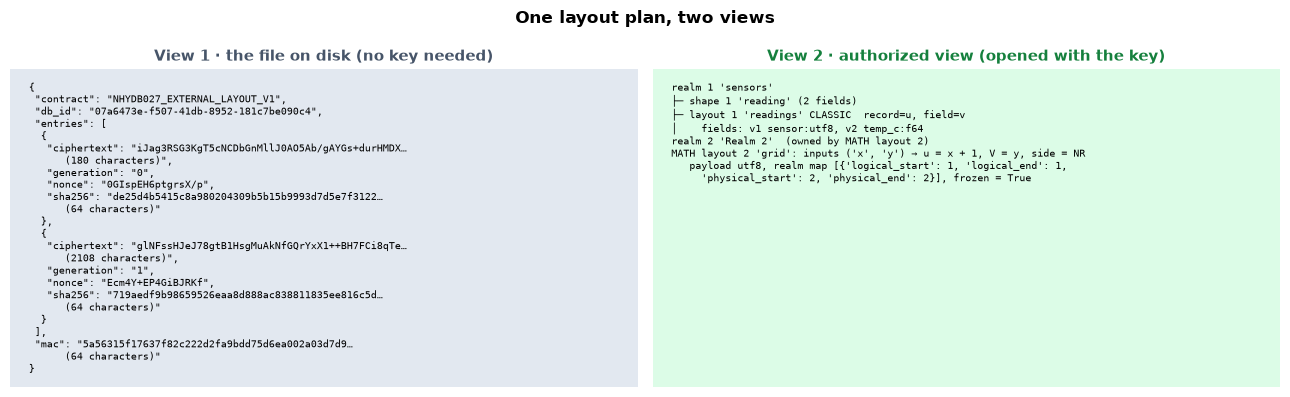

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.0))
import textwrap
enc_text = json.dumps(view1, indent=1, ensure_ascii=False).replace("  (", "\n      (")
view2_text = "\n".join(textwrap.fill(line, 78, subsequent_indent="     ") for line in VIEW2.splitlines())
for ax, title, text, layer in ((ax1, "View 1 · the file on disk (no key needed)", enc_text, "C"),
                               (ax2, "View 2 · authorized view (opened with the key)", view2_text, "B")):
    ax.add_patch(FancyBboxPatch((0, 0), 1, 1, boxstyle="round,pad=0.01,rounding_size=0.02",
                                facecolor=COLORS[layer + "_light"], edgecolor=COLORS[layer], lw=1.5,
                                transform=ax.transAxes))
    ax.text(0.03, 0.96, text, va="top", ha="left", family="monospace", fontsize=7, transform=ax.transAxes)
    ax.set_title(title, color=COLORS[layer])
    ax.axis("off")
fig.suptitle("One layout plan, two views", fontweight="bold")
plt.tight_layout()
plt.show()

## 5 · Every schema change is a new plan generation

**Question:** What happens to the plan when the schema changes?

▶ **Run it:** we keep a copy of the current plan file, then add an index. The commit seals a new
generation, rewrites the plan with **[previous, new]** generation and records the new
generation and schema digest in R0,u1.

In [8]:
OLD_PLAN = os.path.join(WORKDIR, "plan_before_index.enc")
shutil.copy2(LIVE + ".layout.enc", OLD_PLAN)


def generation_state(path):
    with nhydb.open(path) as db:
        cells = db.get_system_metadata()["cells"]
    entries = json.load(open(path + ".layout.enc"))["entries"]
    return {"R0,u1 generation": cells["5"], "R0,u1 digest": cells["6"][:12] + "…",
            "plan holds generations": [e["generation"] for e in entries]}


before = generation_state(LIVE)
with nhydb.open(LIVE) as db:
    db.create_index(1, 1, "by_sensor", "sensor")
    db.build_indexes(commit=True)
after = generation_state(LIVE)
assert after["R0,u1 generation"] == before["R0,u1 generation"] + 1
pd.DataFrame([before, after], index=["before the index", "after the index"])

,"R0,u1 generation","R0,u1 digest",plan holds generations
before the index,1,719aedf9b986…,"[0, 1]"
after the index,2,f29d34b80269…,"[1, 2]"


**What happened?** The generation went up by one and the schema digest changed. The plan keeps
exactly two generations, so that a crash between writing the plan and the data file's commit
can always be resolved (Technical documentation, section 8.5).

## 6 · The attack lab

**Question:** What happens if files are missing, swapped or manipulated?

Every scenario works on a **fresh copy** of the three files; the original database is never
touched. A second database with the **same file name** serves as the "foreign" source for swapped
files. For each scenario we try to open the copy and read the known values.

In [9]:
other_dir = os.path.join(WORKDIR, "other")
os.makedirs(other_dir, exist_ok=True)
OTHER = os.path.join(other_dir, "plant.nhydb")               # same name, different database
with nhydb.create(OTHER) as db:
    db.create_realm(1, "something else")


def flip_char(path, field):
    # change one character inside a JSON field of the plan file
    data = json.load(open(path))
    target = data["entries"][-1] if field == "ciphertext" else data
    s = target[field]
    target[field] = s[:10] + ("A" if s[10] != "A" else "B") + s[11:]
    json.dump(data, open(path, "w"))


def flip_data_byte(path):
    # change one byte of a stored value in the data file ('boiler' -> 'Boiler')
    raw = bytearray(open(path, "rb").read())
    pos = raw.index(b"boiler")
    raw[pos] ^= 0x20
    open(path, "wb").write(raw)


def rename_data(path):
    new = os.path.join(os.path.dirname(path), "renamed.nhydb")
    os.rename(path, new)
    return new, {"layout_path": path + ".layout.enc", "key_path": path + ".layout.key"}


SCENARIOS = [
    ("intact copy (control)",            lambda p: None),
    ("key file missing",                 lambda p: os.remove(p + ".layout.key")),
    ("plan file missing",                lambda p: os.remove(p + ".layout.enc")),
    ("one character of ciphertext",      lambda p: flip_char(p + ".layout.enc", "ciphertext")),
    ("one character of the MAC",         lambda p: flip_char(p + ".layout.enc", "mac")),
    ("key of another database",          lambda p: shutil.copy2(OTHER + ".layout.key", p + ".layout.key")),
    ("plan of another database",         lambda p: shutil.copy2(OTHER + ".layout.enc", p + ".layout.enc")),
    ("data file renamed",                rename_data),
    ("one byte of a value in the data",  flip_data_byte),
]

lab = []
for i, (name, attack) in enumerate(SCENARIOS):
    path = copy_db(LIVE, os.path.join(WORKDIR, f"lab_{i}"))
    changed = attack(path)
    options = {}
    if isinstance(changed, tuple):
        path, options = changed
    try:
        values = read_known_values(path, **options)
        lab.append({"scenario": name, "opened": True, "result": f"values read: {values == EXPECTED}"})
    except Exception as e:
        lab.append({"scenario": name, "opened": False, "result": short(e)})

lab = pd.DataFrame(lab).set_index("scenario")
assert lab["opened"].tolist() == [True] + [False] * 8
pd.set_option("display.max_colwidth", 110)
lab

,opened,result
scenario,,
intact copy (control),True,values read: True
key file missing,False,FileNotFoundError: [Errno 2] No such file or directory: 'plant.nhydb.layout.key'
plan file missing,False,FileNotFoundError: [Errno 2] No such file or directory: 'plant.nhydb.layout.enc'
one character of ciphertext,False,CorruptionError: Layout plan: integrity check failed
one character of the MAC,False,CorruptionError: Layout plan: integrity check failed
key of another database,False,CorruptionError: Wrong layout key file (database ID or name does not match)
plan of another database,False,CorruptionError: External layout plan does not belong to the database
data file renamed,False,"CorruptionError: DB file name 'renamed.nhydb' does not match the name 'plant.nhydb' bound in R0,u1: the da..."
one byte of a value in the data,False,CorruptionError: block 3: payload CRC mismatch


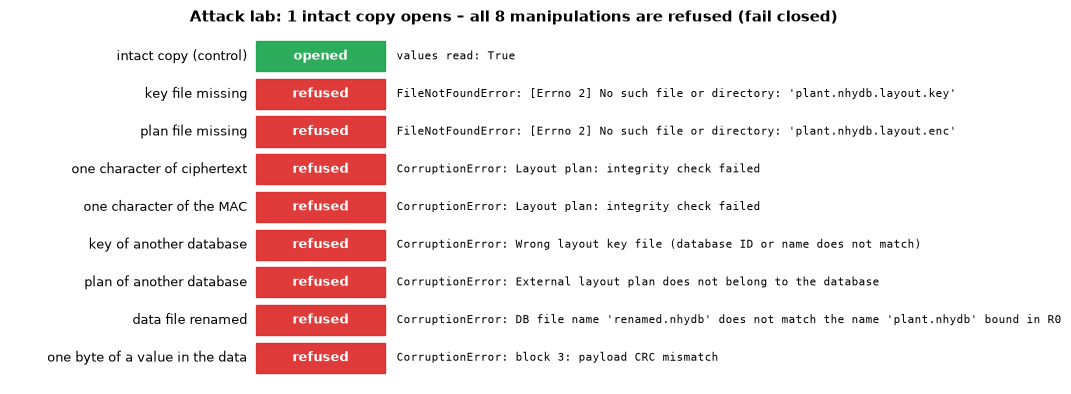

In [10]:
fig, ax = plt.subplots(figsize=(13, 4.6))
for i, (name, row) in enumerate(lab.iterrows()):
    y = len(lab) - 1 - i
    color = COLORS["ok"] if row["opened"] else COLORS["bad"]
    ax.add_patch(Rectangle((0, y - 0.4), 2.2, 0.8, color=color, alpha=0.9))
    ax.text(1.1, y, "opened" if row["opened"] else "refused", ha="center", va="center", color="white",
            fontweight="bold", fontsize=9)
    ax.text(-0.15, y, name, ha="right", va="center", fontsize=9)
    ax.text(2.4, y, row["result"][:95], va="center", fontsize=8, family="monospace")
ax.set_xlim(-4.2, 13)
ax.set_ylim(-0.7, len(lab) - 0.3)
ax.axis("off")
ax.set_title("Attack lab: 1 intact copy opens – all 8 manipulations are refused (fail closed)")
plt.show()

**What happened? – fail closed**

* Missing files: the engine cannot even start (`FileNotFoundError`).
* One changed character in the ciphertext or the MAC: the HMAC check fails before anything is
  decrypted (`integrity check failed`).
* Files from another database – even with the same file name – are recognized by the database
  id (`Wrong layout key file`, `does not belong to the database`).
* A renamed data file no longer matches the name stored in R0,u1.
* A single changed byte of a stored value is caught by the block checksum (CRC) of the data file.

In every case the engine **refuses to open** instead of returning wrong or partial data.
**Ah – the three files only work as a set, and only unchanged.**

## 7 · Restore the originals – and everything works again

The attack lab only touched copies. To show the repair path, we damage a "live" copy, see it
fail, put the exact original bytes of plan and key back (the key file again with permissions
`0600` – otherwise NHyDB warns that others can read it), and read the same values again.

In [11]:
work = copy_db(LIVE, os.path.join(WORKDIR, "restore_demo"))
saved = {s: open(work + s, "rb").read() for s in (".layout.enc", ".layout.key")}   # exact bytes

flip_char(work + ".layout.enc", "mac")
os.remove(work + ".layout.key")
try:
    read_known_values(work)
except (FileNotFoundError, nhydb.CorruptionError) as e:
    print("damaged copy →", short(e))

for suffix, content in saved.items():                                                # restore
    open(work + suffix, "wb").write(content)
os.chmod(work + ".layout.key", 0o600)                                                # key stays private
restored_values = read_known_values(work)
print("after restoring the original bytes:", restored_values)
assert restored_values == EXPECTED

damaged copy → FileNotFoundError: [Errno 2] No such file or directory: 'plant.nhydb.layout.key'
after restoring the original bytes: ('boiler', 40.25, 'calibration 2026')


## 8 · Keep the key somewhere else

The key file does not have to lie next to the data. Pass `key_path` when creating the database
and every time you open it (or put the path into the configuration file, Cookbook section 19).
Whoever copies only the data folder cannot open the database.

In [12]:
data_dir = os.path.join(WORKDIR, "data_only")
key_dir = os.path.join(WORKDIR, "key_vault")
os.makedirs(data_dir)
os.makedirs(key_dir)
SECURE = os.path.join(data_dir, "secure.nhydb")
KEY = os.path.join(key_dir, "secure.nhydb.layout.key")

with nhydb.create(SECURE, key_path=KEY) as db:
    db.create_realm(1, "r")
    db.put_cell(1, 1, 1, "inside", type="utf8")
print("data folder:", sorted(os.listdir(data_dir)))
print("key folder: ", sorted(os.listdir(key_dir)))
print("key file permissions:", oct(os.stat(KEY).st_mode & 0o777) if os.name == "posix" else "(Windows ACL)")

try:
    nhydb.open(SECURE)
except FileNotFoundError as e:
    print("without key_path →", type(e).__name__)
with nhydb.open(SECURE, key_path=KEY) as db:
    assert db.get_value(1, 1, 1) == "inside"
    print("with key_path    → opened:", db.get_value(1, 1, 1))

data folder: ['secure.nhydb', 'secure.nhydb.layout.enc', 'secure.nhydb.lock']
key folder:  ['secure.nhydb.layout.key']
key file permissions: 0o600
without key_path → FileNotFoundError
with key_path    → opened: inside


## 9 · The honest limits

The plan protection is about the **schema** and about **refusing** inconsistent files. It does
not make the stored values secret: the data file is written in plain form.

In [13]:
raw_data = open(LIVE, "rb").read()
visible = {word: word.encode() in raw_data for word in ("boiler", "pump", "calibration 2026")}
hidden = {word: word.encode() in raw_data for word in ("readings", "temp_c", "x + 1")}
print("values visible in the data file:     ", visible)
print("schema names visible in the data file:", hidden)
assert all(visible.values()) and not any(hidden.values())

values visible in the data file:      {'boiler': True, 'pump': True, 'calibration 2026': True}
schema names visible in the data file: {'readings': False, 'temp_c': False, 'x + 1': False}


**What happened?** Values such as `boiler` or `calibration 2026` can be found with a simple byte
search in `plant.nhydb`; names of layouts, fields and formulas cannot. Without the plan nobody can
reliably tell which bytes belong to which record, field or formula – but this is **no**
encryption of the data. Protect data files with file-system permissions or disk encryption, and
keep a backup of the key file: a lost key cannot be recovered.

| What the plan protection does | What it does not do |
|---|---|
| keeps the schema (layouts, fields, MATH formulas, indexes) encrypted | encrypt the stored values |
| binds data, plan and key to each other (id, name, generation, digest) | replace backups – a lost key is lost |
| refuses to open on any missing or manipulated file | protect against someone who has all three files |

## Your turn

**Task:** we kept a copy of the plan file from **before** the index was added (section 5). What
happens if a backup mix-up puts this older plan next to the current data file? Predict first.

In [14]:
# Solution: the data file says "generation g+1"; the old plan only knows generations up to g → refused.
mixup = copy_db(LIVE, os.path.join(WORKDIR, "mixup"))
shutil.copy2(OLD_PLAN, mixup + ".layout.enc")
try:
    read_known_values(mixup)
    outcome = "opened"
except nhydb.CorruptionError as e:
    outcome = short(e)
print("old plan + new data →", outcome)
assert outcome.startswith("CorruptionError")

old plan + new data → CorruptionError: no layout plan matching R0,u1 generation and hash


## ⏩ Advanced: how the plan file is built

From the technical documentation (section 8.3) – for readers who want the details:

* **Key file:** JSON `{"contract": "NHYDB027_KEY_V1", "db_id", "db_name", "key_b64"}` with
  32 random bytes, created exclusively with permissions `0600`.
* **Plan file:** JSON `{"contract": "NHYDB027_EXTERNAL_LAYOUT_V1", "db_id", "entries": [1..2], "mac"}`;
  `mac = HMAC-SHA256(SHA256("NHYDB027-LAYOUT-MAC:" ‖ key), envelope without mac)`.
* **Entry:** `{"generation", "sha256", "nonce", "ciphertext"}`, AES-256-GCM with a 12-byte random
  nonce and the additional authenticated data `"NHYDB027:{db_id}:{generation}:{sha256}"`. The
  field `sha256` holds the schema digest `HMAC-SHA256(SHA256("NHYDB027-SCHEMA-DIGEST:" ‖ key), schema)`
  – a guessed schema cannot be confirmed without the key.
* **Opening:** read superblocks → read the block directory and scan the remaining blocks → check
  file name against R0,u1 → load key → check MAC → find the entry with R0's generation and
  digest → decrypt → check digest and contract → only then cut an uncommitted tail. Any error
  before the last step leaves the file unchanged.

## Summary

* Data (`.nhydb`), plan (`.layout.enc`) and key (`.layout.key`) form one set, bound by id, name, generation and schema digest.
* The plan file shows only an envelope; the schema is AES-256-GCM ciphertext with an HMAC-SHA256 MAC.
* The authorized view – the full schema – exists only inside an opened database.
* Every schema change seals a new generation; the plan keeps the current and the previous one.
* All eight manipulations were refused; the data file itself is not encrypted – protect it like any file.

## Where to go next

* [11 · What Actually Lives on Disk?](11_what_lives_on_disk_v1.ipynb) – backups and the commit boundary.
* [14 · Build a Small Real Application](14_complete_application_v1.ipynb) – everything together.

**Cookbook sections:** 21 (Database files, backup), 23 (System space R0,u1), 19 (Configuration: key_path) in the [NHyDB Python Cookbook](https://github.com/nhydb-run4/NHyDB/blob/main/docs/cookbook/PYTHON_COOKBOOK.md).

In [15]:
# Clean up: remove the temporary folder with all databases of this notebook.
cleanup()
print("Temporary files removed.")

Temporary files removed.
